In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# All filenames are taken from your project folder
files = {
    "holdout": "forecast_holdout_i16.csv",
    "daily_forecast": "forecast_daily_i16.csv",
    "backtest": "ts_backtest_i16.csv",
    "hourly": "time_series_hourly.csv",
    "daily": "time_series_daily.csv",
    "clean": "acn_clean_sessions.csv"
}

# Check that files exist in the current working directory
for name, filename in files.items():
    if not Path(filename).exists():
        print(f"File not found in current directory: {filename}")

# Load the existing forecasting outputs
holdout_df = pd.read_csv(files["holdout"])
daily_forecast_df = pd.read_csv(files["daily_forecast"])
backtest_df = pd.read_csv(files["backtest"])

print("HOLDOUT FORECAST")
print(holdout_df.shape)
print(holdout_df.columns.tolist())
display(holdout_df.head())

print("\nDAILY FORECAST")
print(daily_forecast_df.shape)
print(daily_forecast_df.columns.tolist())
display(daily_forecast_df.head())

print("\nBACKTEST RESULTS")
print(backtest_df.shape)
print(backtest_df.columns.tolist())
display(backtest_df.head())

HOLDOUT FORECAST
(84, 10)
['date', 'actual', 'forecast', 'lo80', 'hi80', 'lo95', 'hi95', 'regime', 'model', 'campus_closure']


,date,actual,forecast,lo80,hi80,lo95,hi95,regime,model,campus_closure
0,2020-01-13,44.0,30.157,22.172,38.143,17.944,42.370,paid,SARIMAX + closures,0
1,2020-01-14,46.0,36.300,28.090,44.510,23.743,48.856,paid,SARIMAX + closures,0
2,2020-01-15,41.0,31.630,23.272,39.987,18.848,44.411,paid,SARIMAX + closures,0
3,2020-01-16,51.0,32.074,23.619,40.528,19.144,45.004,paid,SARIMAX + closures,0
4,2020-01-17,33.0,31.497,22.979,40.016,18.469,44.526,paid,SARIMAX + closures,0



DAILY FORECAST
(56, 11)
['date', 'weekday', 'forecast_sessions', 'lo80', 'hi80', 'lo95', 'hi95', 'campus_closure', 'forecast_kWh', 'expected_peak_plugged_in', 'peak_plugged_in_upper']


,date,weekday,forecast_sessions,lo80,hi80,lo95,hi95,campus_closure,forecast_kWh,expected_peak_plugged_in,peak_plugged_in_upper
0,2021-09-14,Tue,28.44,24.22,32.67,21.98,34.90,0,344.58,18.45,27.96
1,2021-09-15,Wed,29.57,25.31,33.84,23.05,36.10,0,358.28,19.29,28.85
2,2021-09-16,Thu,27.31,23.01,31.61,20.73,33.89,0,330.85,17.61,27.21
3,2021-09-17,Fri,30.05,25.72,34.38,23.42,36.67,0,364.02,19.65,29.27
4,2021-09-18,Sat,15.39,11.04,19.75,8.73,22.05,0,186.48,8.77,18.42



BACKTEST RESULTS
(12, 10)
['regime', 'model', 'MAE', 'RMSE', 'WAPE', 'bias_actual_minus_forecast', 'MAE_closure_days', 'MAE_other_days', 'coverage_80', 'forecasts']


,regime,model,MAE,RMSE,WAPE,bias_actual_minus_forecast,MAE_closure_days,MAE_other_days,coverage_80,forecasts
0,paid,Seasonal naive,7.9732,12.2789,0.3020,-1.1696,25.3462,6.5161,NaN,336
1,paid,8-week weekday mean,6.8207,10.3111,0.2583,-0.1994,24.4087,5.3456,NaN,336
2,paid,"Holt-Winters (damped, log)",7.6691,10.6307,0.2905,0.8068,20.8104,6.5669,NaN,336
3,paid,SARIMA (weekly),6.2080,9.7370,0.2351,-2.0181,25.1291,4.6210,0.8869,336
4,paid,SARIMAX + closures,4.4472,6.1028,0.1684,0.3209,3.9877,4.4858,0.8750,336


In [17]:
def find_column(df, candidates):
    lookup = {str(c).lower().strip(): c for c in df.columns}

    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]

    return None


print("Holdout columns:", holdout_df.columns.tolist())
print("Backtest columns:", backtest_df.columns.tolist())

date_candidates = [
    "timestamp", "datetime", "date", "ds", "time",
    "connectiontime", "period"
]

actual_candidates = [
    "actual", "actual_kwh", "y_true", "y_actual",
    "true", "observed", "observed_kwh", "actual_demand",
    "total_energy_kwh"
]

predicted_candidates = [
    "predicted", "predicted_kwh", "y_pred", "yhat",
    "forecast", "forecast_kwh", "predicted_demand",
    "prediction"
]

print("\nCandidate columns detected:")
print("Holdout date:", find_column(holdout_df, date_candidates))
print("Holdout actual:", find_column(holdout_df, actual_candidates))
print("Holdout predicted:", find_column(holdout_df, predicted_candidates))

Holdout columns: ['date', 'actual', 'forecast', 'lo80', 'hi80', 'lo95', 'hi95', 'regime', 'model', 'campus_closure']
Backtest columns: ['regime', 'model', 'MAE', 'RMSE', 'WAPE', 'bias_actual_minus_forecast', 'MAE_closure_days', 'MAE_other_days', 'coverage_80', 'forecasts']

Candidate columns detected:
Holdout date: date
Holdout actual: actual
Holdout predicted: forecast


In [18]:
actual_col = find_column(holdout_df, actual_candidates)
pred_col = find_column(holdout_df, predicted_candidates)
date_col = find_column(holdout_df, date_candidates)

if actual_col is None or pred_col is None:
    print("Cannot identify actual and predicted columns.")
    print("Review the column names printed in Cell 1 before proceeding.")
else:
    evaluation_df = holdout_df.copy()

    evaluation_df[actual_col] = pd.to_numeric(
        evaluation_df[actual_col], errors="coerce"
    )
    evaluation_df[pred_col] = pd.to_numeric(
        evaluation_df[pred_col], errors="coerce"
    )

    evaluation_df = evaluation_df.dropna(
        subset=[actual_col, pred_col]
    )

    y_true = evaluation_df[actual_col]
    y_pred = evaluation_df[pred_col]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred) if len(y_true) >= 2 else np.nan

    metrics_df = pd.DataFrame({
        "Metric": ["MAE", "RMSE", "R²", "Test observations"],
        "Value": [mae, rmse, r2, len(evaluation_df)]
    })

    display(metrics_df.round(4))

,Metric,Value
0,MAE,5.1213
1,RMSE,6.4973
2,R²,0.7769
3,Test observations,84.0000


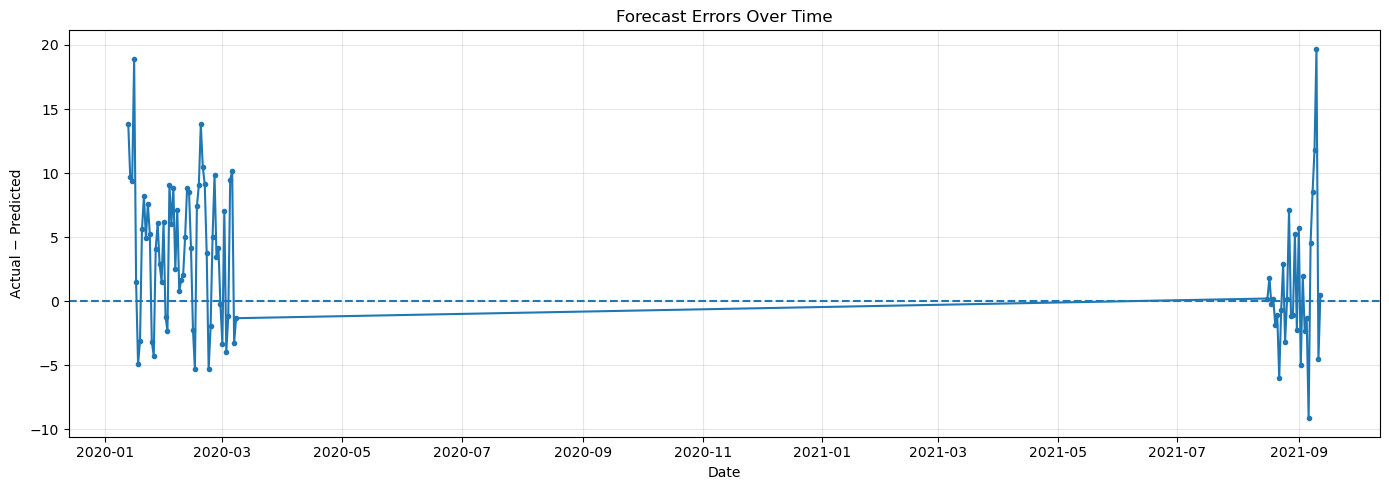

Mean error: 3.0586
MAE: 5.1213
Maximum absolute error: 19.7


,date,actual,forecast,lo80,hi80,lo95,hi95,regime,model,campus_closure,forecast_error,absolute_error
81,2021-09-10,41.0,21.300,16.935,25.665,14.625,27.976,recovery,SARIMAX + closures + drift,0,19.700,19.700
3,2020-01-16,51.0,32.074,23.619,40.528,19.144,45.004,paid,SARIMAX + closures,0,18.926,18.926
0,2020-01-13,44.0,30.157,22.172,38.143,17.944,42.370,paid,SARIMAX + closures,0,13.843,13.843
37,2020-02-19,46.0,32.161,22.861,41.460,17.938,46.383,paid,SARIMAX + closures,0,13.839,13.839
80,2021-09-09,34.0,22.211,17.852,26.571,15.544,28.879,recovery,SARIMAX + closures + drift,0,11.789,11.789
38,2020-02-20,43.0,32.508,23.206,41.811,18.281,46.735,paid,SARIMAX + closures,0,10.492,10.492
53,2020-03-06,42.0,31.853,22.343,41.363,17.309,46.397,paid,SARIMAX + closures,0,10.147,10.147
44,2020-02-26,42.0,32.161,22.758,41.564,17.781,46.541,paid,SARIMAX + closures,0,9.839,9.839
1,2020-01-14,46.0,36.300,28.090,44.510,23.743,48.856,paid,SARIMAX + closures,0,9.700,9.700
52,2020-03-05,42.0,32.509,23.001,42.016,17.968,47.049,paid,SARIMAX + closures,0,9.491,9.491


In [19]:
if actual_col is not None and pred_col is not None:
    evaluation_df["forecast_error"] = (
        evaluation_df[actual_col] - evaluation_df[pred_col]
    )
    evaluation_df["absolute_error"] = (
        evaluation_df["forecast_error"].abs()
    )

    error_plot_df = evaluation_df.copy()
    error_plot_df[date_col] = pd.to_datetime(
        error_plot_df[date_col], errors="coerce", utc=True
    )
    error_plot_df = error_plot_df.dropna(
        subset=[date_col]
    ).sort_values(date_col)

    plt.figure(figsize=(14, 5))
    plt.plot(
        error_plot_df[date_col],
        error_plot_df["forecast_error"],
        marker="."
    )
    plt.axhline(0, linestyle="--")
    plt.title("Forecast Errors Over Time")
    plt.xlabel("Date")
    plt.ylabel("Actual − Predicted")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("Mean error:", round(evaluation_df["forecast_error"].mean(), 4))
    print("MAE:", round(evaluation_df["absolute_error"].mean(), 4))
    print("Maximum absolute error:",
          round(evaluation_df["absolute_error"].max(), 4))

    display(
        evaluation_df.nlargest(10, "absolute_error")
    )

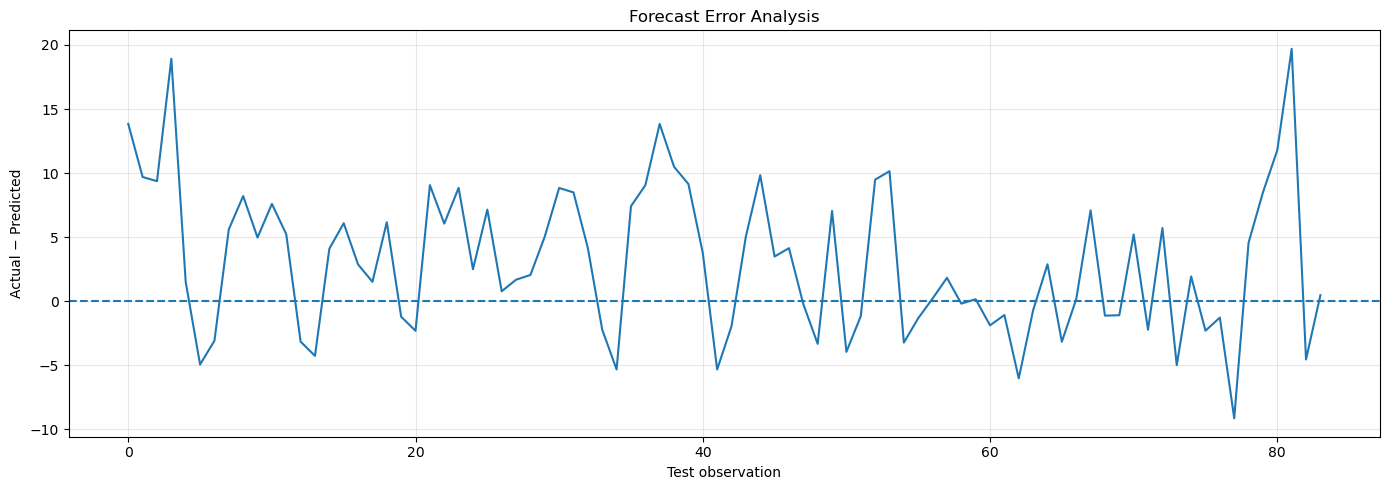

Mean error: 3.0586
Mean absolute error: 5.1213
Maximum absolute error: 19.7

10 observations with the largest errors:


,date,actual,forecast,lo80,hi80,lo95,hi95,regime,model,campus_closure,forecast_error,absolute_error
81,2021-09-10,41.0,21.300,16.935,25.665,14.625,27.976,recovery,SARIMAX + closures + drift,0,19.700,19.700
3,2020-01-16,51.0,32.074,23.619,40.528,19.144,45.004,paid,SARIMAX + closures,0,18.926,18.926
0,2020-01-13,44.0,30.157,22.172,38.143,17.944,42.370,paid,SARIMAX + closures,0,13.843,13.843
37,2020-02-19,46.0,32.161,22.861,41.460,17.938,46.383,paid,SARIMAX + closures,0,13.839,13.839
80,2021-09-09,34.0,22.211,17.852,26.571,15.544,28.879,recovery,SARIMAX + closures + drift,0,11.789,11.789
38,2020-02-20,43.0,32.508,23.206,41.811,18.281,46.735,paid,SARIMAX + closures,0,10.492,10.492
53,2020-03-06,42.0,31.853,22.343,41.363,17.309,46.397,paid,SARIMAX + closures,0,10.147,10.147
44,2020-02-26,42.0,32.161,22.758,41.564,17.781,46.541,paid,SARIMAX + closures,0,9.839,9.839
1,2020-01-14,46.0,36.300,28.090,44.510,23.743,48.856,paid,SARIMAX + closures,0,9.700,9.700
52,2020-03-05,42.0,32.509,23.001,42.016,17.968,47.049,paid,SARIMAX + closures,0,9.491,9.491


In [20]:
if actual_col is not None and pred_col is not None:
    evaluation_df["forecast_error"] = (
        evaluation_df[actual_col] - evaluation_df[pred_col]
    )
    evaluation_df["absolute_error"] = (
        evaluation_df["forecast_error"].abs()
    )

    plt.figure(figsize=(14, 5))
    plt.plot(evaluation_df["forecast_error"].to_numpy())
    plt.axhline(0, linestyle="--")

    plt.title("Forecast Error Analysis")
    plt.xlabel("Test observation")
    plt.ylabel("Actual − Predicted")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("Mean error:", round(evaluation_df["forecast_error"].mean(), 4))
    print("Mean absolute error:", round(evaluation_df["absolute_error"].mean(), 4))
    print("Maximum absolute error:", round(evaluation_df["absolute_error"].max(), 4))

    print("\n10 observations with the largest errors:")
    display(
        evaluation_df.nlargest(10, "absolute_error")
    )

In [21]:
if actual_col is not None and pred_col is not None:
    evaluation_df.to_csv(
        "forecast_evaluation_i17.csv", index=False
    )

    metrics_df.to_csv(
        "forecast_evaluation_metrics_i17.csv", index=False
    )

    print("Saved:")
    print("- forecast_evaluation_i17.csv")
    print("- forecast_evaluation_metrics_i17.csv")

Saved:
- forecast_evaluation_i17.csv
- forecast_evaluation_metrics_i17.csv


In [22]:
# Issue #17: Compare forecast performance by model and regime

group_results = []

for (model_name, regime_name), group in evaluation_df.groupby(
    ["model", "regime"]
):
    group_results.append({
        "Model": model_name,
        "Regime": regime_name,
        "Observations": len(group),
        "Actual Mean": group[actual_col].mean(),
        "Predicted Mean": group[pred_col].mean(),
        "MAE": mean_absolute_error(
            group[actual_col], group[pred_col]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                group[actual_col], group[pred_col]
            )
        )
    })

regime_metrics = pd.DataFrame(group_results)

display(regime_metrics.round(4))

,Model,Regime,Observations,Actual Mean,Predicted Mean,MAE,RMSE
0,SARIMAX + closures,paid,56,29.4821,25.4402,5.7194,6.8212
1,SARIMAX + closures + drift,recovery,28,20.5714,19.4796,3.9251,5.7956


In [23]:
print("Observations by model and regime:")

display(
    evaluation_df.groupby(["model", "regime"])
    .agg(
        observations=(actual_col, "size"),
        actual_mean=(actual_col, "mean"),
        predicted_mean=(pred_col, "mean"),
        MAE=(actual_col, lambda x: np.nan)
    )
)

# Calculate MAE correctly for each model/regime group
group_results = []

for (model_name, regime_name), group in evaluation_df.groupby(
    ["model", "regime"]
):
    group_mae = mean_absolute_error(
        group[actual_col], group[pred_col]
    )
    group_results.append({
        "Model": model_name,
        "Regime": regime_name,
        "Observations": len(group),
        "MAE": group_mae
    })

display(pd.DataFrame(group_results))

Observations by model and regime:


,,observations,actual_mean,predicted_mean,MAE
model,regime,,,,
SARIMAX + closures,paid,56,29.482143,25.440196,NaN
SARIMAX + closures + drift,recovery,28,20.571429,19.479607,NaN


,Model,Regime,Observations,MAE
0,SARIMAX + closures,paid,56,5.719375
1,SARIMAX + closures + drift,recovery,28,3.925107
